# Synthetic sales practice: my first analysis notebook
**Milestone 3.** All data here is fictional/synthetic practice data (8 made-up orders). Upload `sales.csv` and `sales-dirty.csv` beside this notebook (Colab: Files → Upload), then run cells top to bottom.

## Required check 1: Load the CSV and show the first rows

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('sales.csv')
print('Shape (rows, columns):', df.shape)
display(df.head())

Shape (rows, columns): (8, 6)


,OrderID,Date,Region,Category,Quantity,UnitPrice
0,S01,2026-01-01,West,Books,2,200
1,S02,2026-01-02,East,Bags,1,800
2,S03,2026-01-03,West,Books,3,200
3,S04,2026-01-04,North,Pens,10,20
4,S05,2026-01-05,South,Bags,2,800


## Required check 2: Count missing values and explain a cleaning decision

In [2]:
print('Missing values in sales.csv:')
print(df.isna().sum())
print('Total missing:', df.isna().sum().sum())

Missing values in sales.csv:
OrderID      0
Date         0
Region       0
Category     0
Quantity     0
UnitPrice    0
dtype: int64
Total missing: 0


`sales.csv` has **no missing values**, so there is nothing to fix there. To practise cleaning, I also load `sales-dirty.csv`, which has problems on purpose.

In [3]:
dirty = pd.read_csv('sales-dirty.csv')
print('Rows before cleaning:', len(dirty))
print()
print('Missing values per column:')
print(dirty.isna().sum())
print()
print('Duplicate OrderIDs (ignoring blanks):', dirty['OrderID'].dropna().duplicated().sum())
display(dirty.tail(3))

Rows before cleaning: 10

Missing values per column:
OrderID      1
Date         1
Region       1
Category     1
Quantity     1
UnitPrice    1
dtype: int64

Duplicate OrderIDs (ignoring blanks): 1


,OrderID,Date,Region,Category,Quantity,UnitPrice
7,S08,2026-01-08,North,Books,1.0,200.0
8,S03,2026-01-03,West,Books,3.0,200.0
9,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Cleaning decision: drop completely empty rows, then drop repeated OrderIDs (keep the first).
clean = dirty.dropna(how='all')
clean = clean.drop_duplicates(subset='OrderID', keep='first')
# The blank row made Quantity/UnitPrice decimals (floats); turn them back into whole numbers.
clean = clean.astype({'Quantity': 'int64', 'UnitPrice': 'int64'})

print('Rows after cleaning:', len(clean))
print('Missing values left:', clean.isna().sum().sum())
print('Matches sales.csv exactly:', clean.reset_index(drop=True).equals(df))

Rows after cleaning: 8
Missing values left: 0
Matches sales.csv exactly: True


**My cleaning decision:** I dropped the fully blank row because it has no order information, so it can't be analysed and would only add missing values. I also dropped the second `S03` row because `OrderID` should be unique, so it is the same order recorded twice. Keeping it would count that order's revenue two times and inflate the totals. I kept the *first* copy of `S03`. After cleaning, the 10 rows became 8, matching `sales.csv`.

## Required check 3: Total revenue and average order value

In [5]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

total_revenue = df['Revenue'].sum()
avg_order_value = df['Revenue'].mean()   # one row = one order (OrderID is unique)

print('Orders:', len(df))
print('Total revenue:', total_revenue)
print('Average order value:', avg_order_value)

Orders: 8
Total revenue: 4700
Average order value: 587.5


Check against the pack's expected result: 8 orders, revenue 4700, average 587.5.

In [6]:
assert len(df) == 8
assert total_revenue == 4700
assert avg_order_value == 587.5
print('All three numbers match the expected values')

All three numbers match the expected values


## Required check 4: Category bar chart

Category
Bags     3200
Books    1200
Pens      300
Name: Revenue, dtype: int64

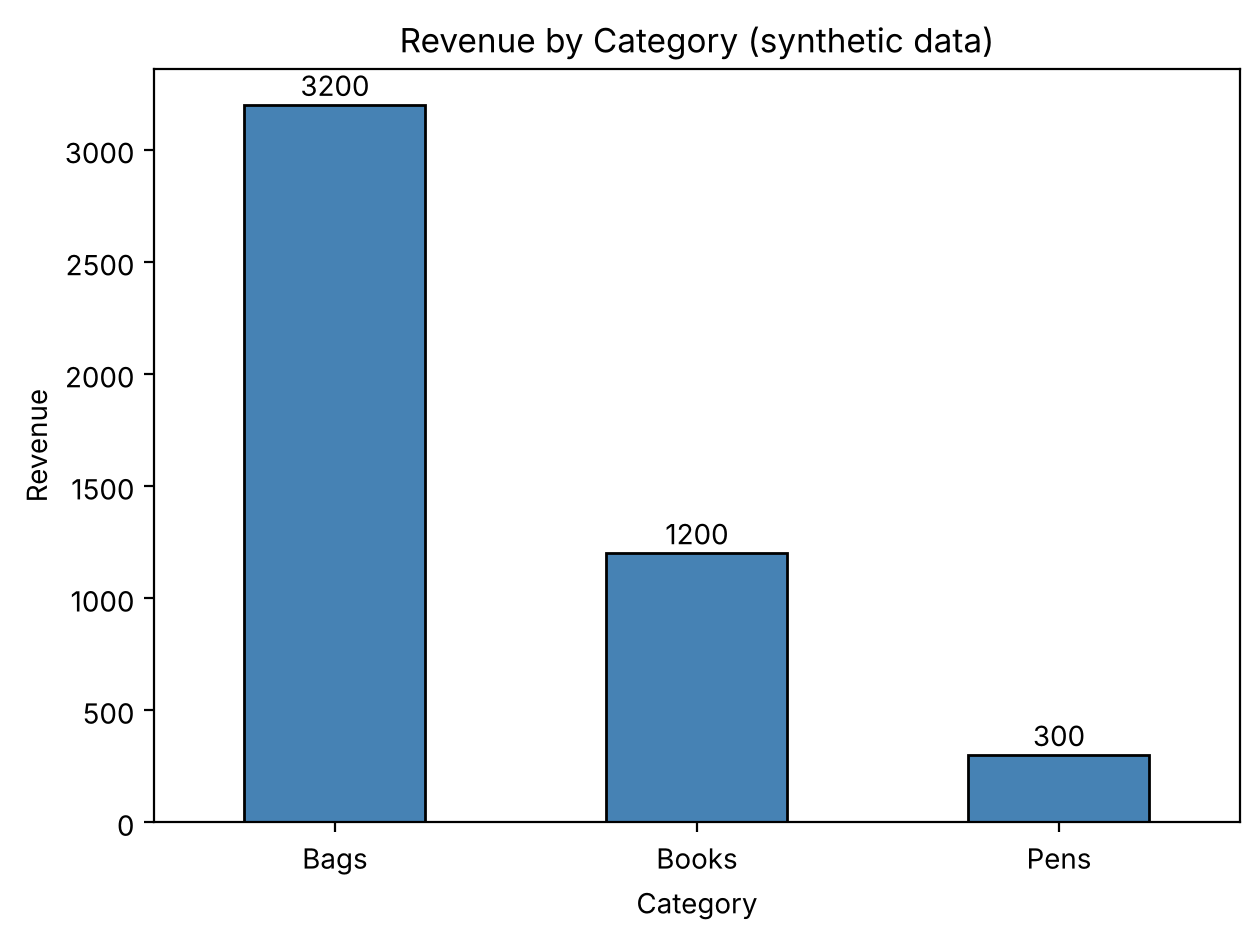

In [7]:
cat_revenue = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
display(cat_revenue)

ax = cat_revenue.plot(kind='bar', color='steelblue', edgecolor='black')
ax.set_title('Revenue by Category (synthetic data)')
ax.set_xlabel('Category')
ax.set_ylabel('Revenue')
plt.xticks(rotation=0)
for i, v in enumerate(cat_revenue):
    ax.text(i, v + 40, str(v), ha='center')
plt.tight_layout()
plt.show()

In [8]:
# Numbers behind my observations
share = (cat_revenue / cat_revenue.sum() * 100).round(1)
print('Share of revenue (%):'); print(share)
print()
print('Units sold per category:'); print(df.groupby('Category')['Quantity'].sum())
print()
print('Orders per category:'); print(df.groupby('Category').size())

Share of revenue (%):
Category
Bags     68.1
Books    25.5
Pens      6.4
Name: Revenue, dtype: float64

Units sold per category:
Category
Bags      4
Books     6
Pens     15
Name: Quantity, dtype: int64

Orders per category:
Category
Bags     3
Books    3
Pens     2
dtype: int64


## My observations
*(This dataset is tiny and fictional, so these are practice observations, not real business findings.)*

1. **Bags earn the most.** Bags bring in 3200 of the 4700 total, about 68% of revenue, from only 3 of the 8 orders. Each bag costs 800, so a few sales go a long way.
2. **Volume and revenue are not the same thing.** Pens have the most units sold (15) but the lowest revenue (300, about 6%) because each pen is only 20. Books sit in the middle at 1200.

## Testing: one ordinary case and one boundary case (dummy data)

In [9]:
def summarize(data):
    """Return (order_count, total_revenue, average_order_value)."""
    rev = data['Quantity'] * data['UnitPrice']
    return len(data), rev.sum(), rev.mean()

# Ordinary case: two tiny made-up orders
ordinary = pd.DataFrame({'Quantity': [2, 1], 'UnitPrice': [10, 30]})
print('Ordinary case  ->', summarize(ordinary))   # revenue 20 and 30 => 2, 50, 25.0

# Boundary case: no orders at all (e.g. a filter that matches nothing)
empty = pd.DataFrame({'Quantity': [], 'UnitPrice': []})
print('Boundary case  ->', summarize(empty))

Ordinary case  -> (2, np.int64(50), np.float64(25.0))
Boundary case  -> (0, np.float64(0.0), nan)


**What I found and changed:** For the ordinary case, the result is correct (2 orders, total 50, average 25.0). For the empty case, the total is 0 but the average comes out as `NaN` (not a number), because you can't divide by zero orders. It doesn't crash, but a `NaN` in a report is confusing. So I made the function return `0` for the average when there are no orders.

In [10]:
def summarize_safe(data):
    rev = data['Quantity'] * data['UnitPrice']
    avg = rev.mean() if len(data) > 0 else 0
    return len(data), rev.sum(), avg

print('Ordinary case  ->', summarize_safe(ordinary))
print('Boundary case  ->', summarize_safe(empty))

Ordinary case  -> (2, np.int64(50), np.float64(25.0))
Boundary case  -> (0, np.float64(0.0), 0)


**One thing I learned:** Always test what happens with *empty* data, not just normal data. A calculation that looks fine on 8 rows can give a confusing answer (`NaN`) when a filter removes every row. Also, a duplicate `OrderID` quietly inflates revenue, so checking for duplicates comes before calculating totals.